# Case study: the galaxy velocities

The velocities (km/s) of 82 galaxies in the Corona Borealis region (Roeder, 1990) are a classic multimodal
density-estimation example. The estimators work on [0, 1], so the velocities are divided by a bound fixed in
advance, the speed of light c = 3e5 km/s; the rescaled data then occupy about 8% of [0, 1].

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from haldensity.core.variance import density_confidence_interval, estimate_covariance_beta
from haldensity.datasets import load_galaxies
from haldensity.full_uni import OptunaHyperparameterTuner

data = pd.DataFrame({"W1": load_galaxies()["velocity"].to_numpy() / 3e5})
data["W1"].describe()

count    82.000000
mean      0.069427
std       0.015213
min       0.030573
25%       0.065107
50%       0.069445
75%       0.077110
max       0.114263
Name: W1, dtype: float64

## Fitting grid

At order 2 the fitting objective is normalized on `n_grid_points - 1` equal cells of [0, 1]. With the default
200 points only about 17 cells cover these data and the objective misses part of the fitted mass (the fit warns
and suggests a larger grid). About 200 cells across the data range need roughly 200 / 0.084 = 2,400 points;
1,000 already sees all of the mass here. The tuner gives the same grid to every CV fold and the final fit.

In [2]:
tuner = OptunaHyperparameterTuner("CVXPYEstimator", data, random_state=42, silent=True, show_progress=False,
                                  estimator_kwargs={"n_grid_points": 1000})
tuner.optimize(n_trials=30, show_progress=False)
est = tuner.fit_best_model()
results = est.get_results()
print(f"M = {est.norm_constraint:.4g}, {results['n_selected_knots']} knots, basis cleaning passed: {results['certified']}")
print(f"log_z_gap (accurate log normalizer minus the objective's): {results['log_z_gap']:.1e} nats")

M = 6.538e+05, 82 knots, basis cleaning passed: True
log_z_gap (accurate log normalizer minus the objective's): -5.0e-05 nats


## Density with pointwise 95% intervals

`estimate_covariance_beta` computes the delta-method covariance of the coefficients on the cleaned basis of the
final fit. Its rule adds a ridge of 1e-5 times each basis function's own score variance, so the standard errors
do not depend on the units of the data. `density_confidence_interval` turns it into pointwise intervals,
density ± 1.96 SE with the lower end cut at 0. With 82 observations the intervals are wide; they hold point by
point, not for the whole curve at once. They are drawn over the range of the data: beyond the smallest and the
largest velocity the data carry no information about the density, and the delta method's intervals there
become very wide.

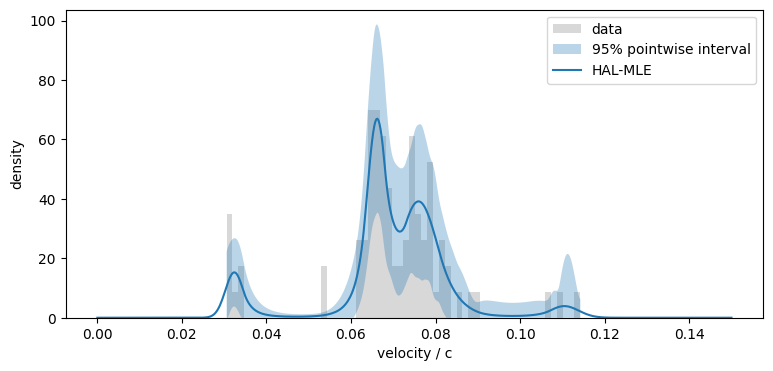

In [3]:
x = np.linspace(0.0, 0.15, 601)
inside = np.linspace(data["W1"].min(), data["W1"].max(), 400)     # the range of the data
cov = estimate_covariance_beta(data, results, basis_order=est.basis_order)
band = density_confidence_interval(inside, results, cov, basis_order=est.basis_order)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(data["W1"], bins=60, density=True, alpha=0.3, color="grey", label="data")
ax.fill_between(band["x"], band["lower"], band["upper"], alpha=0.3, label="95% pointwise interval")
ax.plot(x, est.get_density_at_points(x), label="HAL-MLE")
ax.set_xlabel("velocity / c")
ax.set_ylabel("density")
ax.legend()
plt.show()